# Milestone 3 — EDA dan insight Indonesia News

Analisis temporal dan tujuh visualisasi interaktif dari hasil cleaning Milestone 2. Unit analisis adalah **baris artikel yang dipertahankan**, bukan jumlah peristiwa atau pembaca.

**Batas interpretasi:** kelengkapan arsip tiap media bisa berbeda. Dataset berhenti pada Mei 2020 sehingga 2014 dan 2020 bukan tahun penuh. Unix timestamp ditampilkan sebagai UTC; asal zona waktu timestamp belum diverifikasi. File Tempo tambahan memiliki timestamp dengan presisi lebih rendah, sehingga artikel sama mungkin lolos deduplikasi `source + title + published_at`. Grafik menggunakan definisi cleaning tersebut dan tidak mengklaim semua artikel unik secara semantik.

In [1]:
from pathlib import Path
from IPython.display import display, Markdown
import duckdb
import polars as pl
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "plotly_mimetype"
pio.templates.default = "plotly_white"
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "indonesia_news_clean.parquet"
FIGURE_DIR = PROJECT_ROOT / "output" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError("Jalankan 02_data_cleaning.ipynb terlebih dahulu.")
con = duckdb.connect()
con.from_parquet(str(DATA_PATH)).create_view("news", replace=True)
COLORS = {"CNN Indonesia": "#d62728", "Tempo": "#1f77b4"}
print("Sumber:", DATA_PATH)
print("DuckDB:", duckdb.__version__)

Sumber: /home/jovyan/work/data/processed/indonesia_news_clean.parquet
DuckDB: 1.5.5


## 1. Pemeriksaan data dan pertanyaan analisis

Bagaimana jumlah artikel berubah tiap bulan? Bagaimana komposisi sumber, tag, panjang teks, dan pola hari publikasi? DuckDB melakukan agregasi langsung dari Parquet agar teks seluruh dataset tidak perlu dimuat ke memori.

In [2]:
overview = con.sql("""
SELECT COUNT(*) AS article_count, MIN(published_at) AS first_date,
       MAX(published_at) AS last_date, COUNT(DISTINCT source) AS source_count
FROM news
""").pl()
if overview.item(0, "article_count") == 0:
    raise ValueError("Dataset bersih kosong.")
display(overview)
quality = con.sql("""
SELECT COUNT(*) FILTER (WHERE title IS NULL OR TRIM(title) = '') AS invalid_title,
       COUNT(*) FILTER (WHERE content IS NULL OR content_length < 100) AS invalid_content,
       COUNT(*) FILTER (WHERE published_at IS NULL) AS invalid_date
FROM news
""").pl()
display(quality)
assert all(value == 0 for value in quality.row(0)), "Kualitas data wajib belum terpenuhi."

def show_and_save(fig, filename):
    fig.update_layout(hovermode="closest", margin=dict(t=80, l=60, r=30, b=70))
    fig.write_html(FIGURE_DIR / filename, include_plotlyjs=True, full_html=True)
    fig.show()

total_articles = overview.item(0, "article_count")

article_count,first_date,last_date,source_count
i64,datetime[μs],datetime[μs],i64
964553,2014-08-04 08:35:00,2020-05-31 16:52:00,2


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

invalid_title,invalid_content,invalid_date
i64,i64,i64
0,0,0


## 2. Jumlah artikel per bulan

Grafik 1 memungkinkan zoom dan hover untuk melihat perubahan jumlah artikel tiap media. Bulan tanpa baris diisi nol untuk membedakannya dari titik yang hilang; nol tetap dapat berarti arsip tidak lengkap.

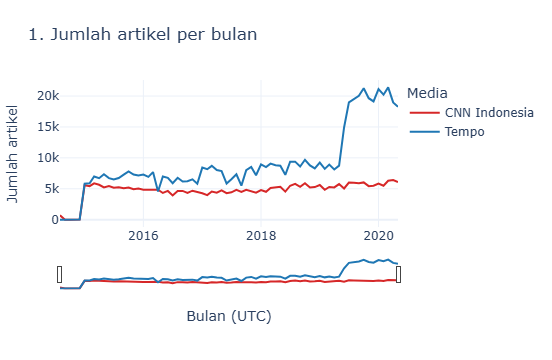

In [3]:
monthly = con.sql("""
WITH bounds AS (
    SELECT MIN(date_trunc('month', published_at)) AS lo,
           MAX(date_trunc('month', published_at)) AS hi FROM news
), months AS (
    SELECT unnest(generate_series(lo, hi, INTERVAL '1 month')) AS month FROM bounds
), sources AS (SELECT DISTINCT source FROM news),
counts AS (
    SELECT date_trunc('month', published_at) AS month, source, COUNT(*) AS article_count
    FROM news GROUP BY 1, 2
)
SELECT m.month, s.source, COALESCE(c.article_count, 0) AS article_count
FROM months m CROSS JOIN sources s
LEFT JOIN counts c ON m.month = c.month AND s.source = c.source
ORDER BY m.month, s.source
""").pl()
fig = px.line(monthly.to_pandas(), x="month", y="article_count", color="source",
              color_discrete_map=COLORS, title="1. Jumlah artikel per bulan",
              labels={"month": "Bulan (UTC)", "article_count": "Jumlah artikel", "source": "Media"})
fig.update_layout(hovermode="x unified")
fig.update_xaxes(rangeslider_visible=True)
show_and_save(fig, "01_monthly_articles.html")

## 3. Jumlah artikel per tahun

Grafik 2 membandingkan arsip tahunan per media. Tahun 2014 dan 2020 diberi keterangan karena periode pengamatan parsial; jangan menafsirkan penurunan 2020 sebagai penurunan satu tahun penuh.

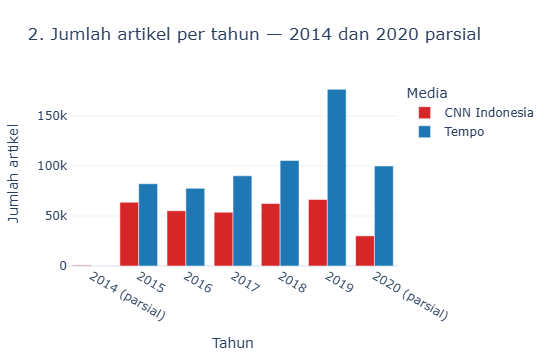

In [4]:
annual = con.sql("""
SELECT year(published_at) AS year, source, COUNT(*) AS article_count
FROM news GROUP BY 1, 2 ORDER BY 1, 2
""").pl().with_columns(
    pl.when(pl.col("year").is_in([2014, 2020]))
    .then(pl.col("year").cast(pl.String) + pl.lit(" (parsial)"))
    .otherwise(pl.col("year").cast(pl.String)).alias("year_label")
)
fig = px.bar(annual.to_pandas(), x="year_label", y="article_count", color="source",
             barmode="group", color_discrete_map=COLORS,
             title="2. Jumlah artikel per tahun — 2014 dan 2020 parsial",
             labels={"year_label": "Tahun", "article_count": "Jumlah artikel", "source": "Media"})
show_and_save(fig, "02_annual_articles.html")

## 4. Komposisi sumber berita

Grafik 3 menunjukkan proporsi baris pada dataset bersih. Proporsi ini menggambarkan arsip dataset dan bukan pangsa pasar media.

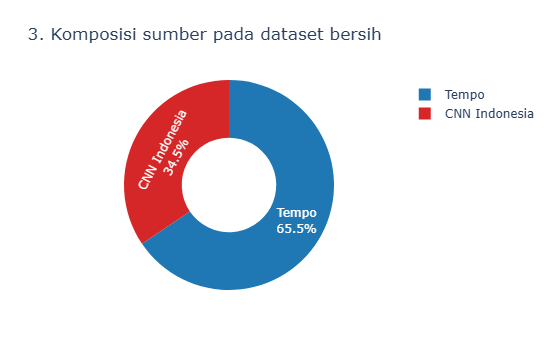

In [5]:
sources = con.sql("""
SELECT source, COUNT(*) AS article_count FROM news GROUP BY source
ORDER BY article_count DESC
""").pl()
fig = px.pie(sources.to_pandas(), names="source", values="article_count", hole=0.45,
             color="source", color_discrete_map=COLORS,
             title="3. Komposisi sumber pada dataset bersih")
fig.update_traces(textinfo="percent+label")
show_and_save(fig, "03_source_share.html")

## 5. Hari dan jam publikasi

Grafik 4 menampilkan jumlah artikel per hari dalam minggu dan jam UTC. Heatmap mengukur volume arsip, bukan produktivitas yang dinormalisasi per hari. Pola jam perlu diperiksa ulang setelah zona waktu sumber dikonfirmasi.

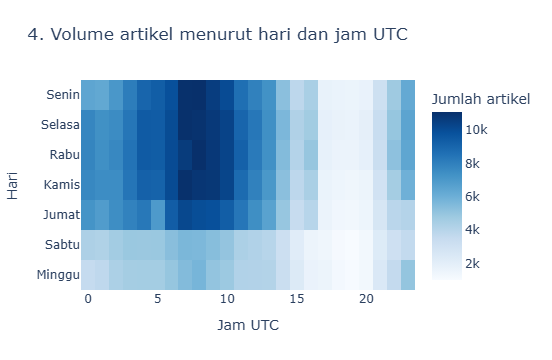

In [6]:
weekday_names = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
hourly = con.sql("""
SELECT isodow(published_at) AS weekday, hour(published_at) AS hour,
       COUNT(*) AS article_count
FROM news GROUP BY 1, 2 ORDER BY 1, 2
""").pl()
matrix = [[0] * 24 for _ in range(7)]
for row in hourly.iter_rows(named=True):
    matrix[row["weekday"] - 1][row["hour"]] = row["article_count"]
fig = px.imshow(matrix, x=list(range(24)), y=weekday_names, aspect="auto",
                color_continuous_scale="Blues", title="4. Volume artikel menurut hari dan jam UTC",
                labels={"x": "Jam UTC", "y": "Hari", "color": "Jumlah artikel"})
fig.update_traces(hovertemplate="%{y}, jam %{x} UTC<br>Artikel: %{z:,}<extra></extra>")
show_and_save(fig, "04_weekday_hour.html")

## 6. Distribusi panjang artikel

Grafik 5 menggunakan jumlah karakter setelah cleaning. Bin 500 karakter dipakai sampai 4.999 karakter dan semua artikel ≥5.000 karakter disatukan dalam bin terakhir, sehingga teks panjang tetap dihitung.

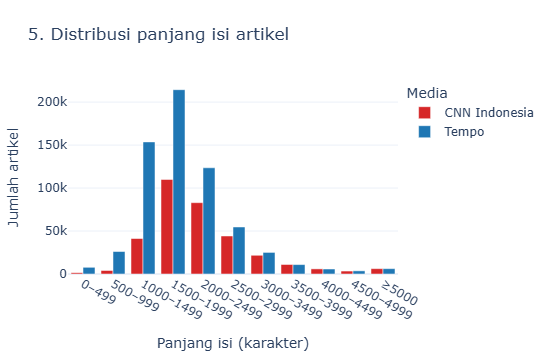

In [7]:
length_bins = con.sql("""
SELECT source, LEAST(CAST(FLOOR(content_length / 500.0) AS INTEGER), 10) AS bin_id,
       COUNT(*) AS article_count
FROM news GROUP BY 1, 2 ORDER BY 2, 1
""").pl().with_columns(
    pl.col("bin_id").map_elements(
        lambda b: f"{b * 500}–{b * 500 + 499}" if b < 10 else "≥5000",
        return_dtype=pl.String
    ).alias("length_bin")
)
assert length_bins["article_count"].sum() == total_articles
fig = px.bar(length_bins.to_pandas(), x="length_bin", y="article_count", color="source",
             barmode="group", color_discrete_map=COLORS,
             category_orders={"length_bin": [f"{i * 500}–{i * 500 + 499}" for i in range(10)] + ["≥5000"]},
             title="5. Distribusi panjang isi artikel",
             labels={"length_bin": "Panjang isi (karakter)", "article_count": "Jumlah artikel", "source": "Media"})
show_and_save(fig, "05_content_length.html")

## 7. Tag yang paling sering muncul

Grafik 6 memisahkan tag dengan koma, merapikan spasi, dan menyamakan huruf kecil. Tag sama yang berulang pada satu artikel hanya dihitung sekali. Artikel tanpa tag dikecualikan dari grafik ini. Tag bukan klasifikasi topik yang seragam antar-media; satu artikel dapat memiliki lebih dari satu tag.

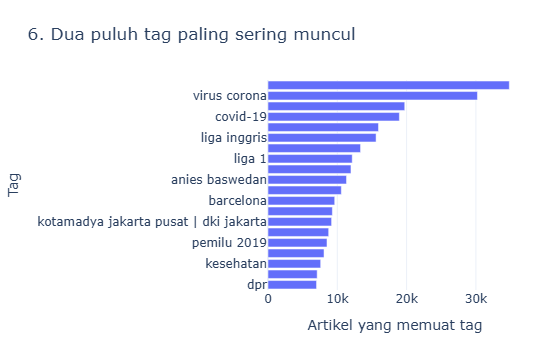

In [8]:
top_tags = con.sql("""
WITH tag_counts AS (
    SELECT unnest(list_distinct(list_transform(
        string_split(tags, ','), x -> lower(trim(x))
    ))) AS tag
    FROM news WHERE tags <> 'Tidak diketahui'
)
SELECT tag, COUNT(*) AS article_count FROM tag_counts
WHERE tag IS NOT NULL AND tag <> ''
GROUP BY tag ORDER BY article_count DESC, tag LIMIT 20
""").pl()
fig = px.bar(top_tags.to_pandas(), x="article_count", y="tag", orientation="h",
             title="6. Dua puluh tag paling sering muncul",
             labels={"article_count": "Artikel yang memuat tag", "tag": "Tag"})
fig.update_yaxes(categoryorder="total ascending")
show_and_save(fig, "06_top_tags.html")

## 8. Perbandingan panjang artikel antar-media

Grafik 7 membandingkan kuartil panjang isi. Kuartil diperoleh dari seluruh baris dengan SQL, tanpa mengirim seluruh teks ke Plotly.

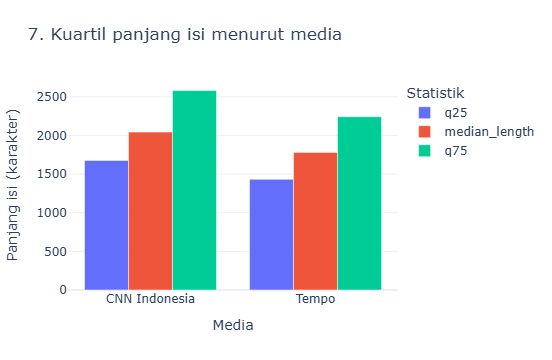

source,q25,median_length,q75,max_length
str,f64,f64,f64,u32
"""CNN Indonesia""",1677.0,2044.0,2582.0,30074
"""Tempo""",1432.0,1781.0,2243.0,52721


In [9]:
length_stats = con.sql("""
SELECT source, quantile_cont(content_length, 0.25) AS q25,
       median(content_length) AS median_length,
       quantile_cont(content_length, 0.75) AS q75,
       MAX(content_length) AS max_length
FROM news GROUP BY source ORDER BY source
""").pl()
quartiles = length_stats.unpivot(
    on=["q25", "median_length", "q75"], index="source",
    variable_name="statistic", value_name="characters"
)
fig = px.bar(quartiles.to_pandas(), x="source", y="characters", color="statistic",
             barmode="group", title="7. Kuartil panjang isi menurut media",
             labels={"source": "Media", "characters": "Panjang isi (karakter)", "statistic": "Statistik"},
             category_orders={"statistic": ["q25", "median_length", "q75"]})
show_and_save(fig, "07_length_quartiles.html")
display(length_stats)

## 9. Insight berdasarkan hasil analisis

Pernyataan berikut dihitung ulang ketika notebook dijalankan. Interpretasi berlaku untuk arsip dataset bersih dan perlu dibaca bersama batasan pada awal notebook.

In [10]:
peak_month = monthly.group_by("month").agg(pl.col("article_count").sum()).sort(
    ["article_count", "month"], descending=[True, False]
).row(0, named=True)
leader = sources.row(0, named=True)
full_years = annual.filter(pl.col("year").is_between(2015, 2019)).group_by("year").agg(
    pl.col("article_count").sum()
).sort(["article_count", "year"], descending=[True, False])
peak_year = full_years.row(0, named=True)
weekday_totals = hourly.group_by("weekday").agg(pl.col("article_count").sum()).sort(
    ["article_count", "weekday"], descending=[True, False]
)
peak_day = weekday_totals.row(0, named=True)
text_leader = length_stats.sort("median_length", descending=True).row(0, named=True)
long_count = length_bins.filter(pl.col("bin_id") == 10)["article_count"].sum()
insights = [
    f"Dataset bersih mencakup **{total_articles:,} artikel** dari "
    f"**{overview.item(0, 'first_date'):%d-%m-%Y}** sampai **{overview.item(0, 'last_date'):%d-%m-%Y}**.",
    f"**{leader['source']}** menyumbang arsip terbanyak, yaitu **{leader['article_count']:,} artikel "
    f"({leader['article_count'] / total_articles * 100:.2f}%)**. Ini proporsi dataset, bukan pangsa pasar.",
    f"Bulan dengan jumlah artikel tertinggi adalah **{peak_month['month']:%Y-%m}**, "
    f"dengan **{peak_month['article_count']:,} artikel** dari kedua media.",
    f"Di antara tahun penuh 2015–2019, **{peak_year['year']}** memiliki arsip terbanyak: "
    f"**{peak_year['article_count']:,} artikel**.",
    f"Akumulasi publikasi tertinggi jatuh pada **{weekday_names[peak_day['weekday'] - 1]}**, "
    f"sebanyak **{peak_day['article_count']:,} artikel** berdasarkan timestamp UTC.",
    f"**{text_leader['source']}** memiliki median isi lebih panjang: "
    f"**{text_leader['median_length']:,.0f} karakter**.",
    f"Sebanyak **{long_count:,} artikel ({long_count / total_articles * 100:.2f}%)** "
    f"memiliki isi minimal 5.000 karakter. Teks panjang dipertahankan untuk analisis.",
]
if top_tags.height:
    first_tag = top_tags.row(0, named=True)
    insights.append(f"Tag paling sering muncul adalah **{first_tag['tag']}**, "
                    f"tercatat pada **{first_tag['article_count']:,} artikel**. "
                    "Tag dihitung setelah pemisahan koma dan normalisasi huruf.")
display(Markdown("\n\n".join(f"{i}. {text}" for i, text in enumerate(insights, 1))))
print("Grafik HTML tersimpan di:", FIGURE_DIR)
con.close()

1. Dataset bersih mencakup **964,553 artikel** dari **04-08-2014** sampai **31-05-2020**.

2. **Tempo** menyumbang arsip terbanyak, yaitu **632,086 artikel (65.53%)**. Ini proporsi dataset, bukan pangsa pasar.

3. Bulan dengan jumlah artikel tertinggi adalah **2020-03**, dengan **27,704 artikel** dari kedua media.

4. Di antara tahun penuh 2015–2019, **2019** memiliki arsip terbanyak: **243,149 artikel**.

5. Akumulasi publikasi tertinggi jatuh pada **Selasa**, sebanyak **164,166 artikel** berdasarkan timestamp UTC.

6. **CNN Indonesia** memiliki median isi lebih panjang: **2,044 karakter**.

7. Sebanyak **12,431 artikel (1.29%)** memiliki isi minimal 5.000 karakter. Teks panjang dipertahankan untuk analisis.

8. Tag paling sering muncul adalah **jokowi**, tercatat pada **34,814 artikel**. Tag dihitung setelah pemisahan koma dan normalisasi huruf.

Grafik HTML tersimpan di: /home/jovyan/work/output/figures


## Status Milestone 3 dan reproduksibilitas

Notebook menghasilkan analisis temporal, tujuh grafik interaktif, dan minimal lima insight. Jalankan notebook cleaning terlebih dahulu, kemudian **Run All Cells** pada notebook ini. Simpan output notebook agar grafik dan insight dapat diperiksa. Salinan grafik HTML di `output/figures/` dapat dibuka tanpa koneksi internet.

**Bantuan AI:** Codex membantu menyusun kode dan penjelasan. Mahasiswa perlu memeriksa hasil eksekusi, memahami aturan cleaning dan batasan arsip, serta mencatat bantuan ini pada AI Disclosure Statement sebelum pengumpulan.